# INX FUTURE INC EMPLOYEE PERFORMANCE - DATA VISUALIZATION

## 1. INTRODUCTION
## 2. VISUALIZATION OBJECTIVE 
## 3. IMPORT REQUIRED LIBRARIES 
## 4. LOAD PROCESSED DATASET
## 5. EMPLOYEE PERFORMANCE DISTRIBUTION 
## 6. DEPARTMENT-WISE PERFORMANCE 
## 7. DEPARTMENT-WISE PERFORMANCE RATING DISTRIBUTION 
## 8. EMPLOYEE SATISFACTION ANALYSIS
## 9. SALARY HIKE ANALYSIS
## 10. PROMOTION ANALYSIS
## 11. WORK-LIFE BALANCE ANALYSIS
## 12. CORRELATION HEATMAP
## 13. TOP THREE IMPORTANT FACTORS
## 14. FEATURE IMPORTANCE VISUALIZATION
## 15. MODEL PERFORMANCE COMPARISON
## 16. CONFUSION MATRIX VISUALIZATION
## 17. KEY VISUAL INSIGHT
## 18. BUSINESS INSIGHT
## 19. CONCLUSION

# INX Future Inc Employee Performance — Data Visualization

## 1. INTRODUCTION

Data visualization is an important part of the employee performance analysis because it converts numerical and categorical information into visual patterns that are easier to understand. In this notebook, visualizations are created to analyze employee performance, department-level patterns, satisfaction, salary hike, promotion, work-life balance, feature importance, model performance, and prediction results.
The visualizations developed in this notebook can be used in the final project report and presentation to communicate technical findings and business insights clearly.


### 1.1 Import Required libraries

In [1]:
# Import required libraries

import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

print(f"Required visualization libraries imported successfully.")


Required visualization libraries imported successfully.


### Insight

The required libraries have been imported successfully. Pandas and NumPy will be used for data manipulation, while Matplotlib and Seaborn will be used to create visualizations.


## 2. VISUALIZATION OBJECTIVE

The objective of this notebook is to visually analyze employee performance and its relationship with important employee characteristics.

The visualization process focuses on identifying patterns, differences between departments, relationships between performance and employee satisfaction, salary hike, promotions, work-life balance, and important factors identified by the trained machine learning model.


### 2.1 Define Project Configuration

In [2]:
# Define project configuration

project_name = "INX_Future_Inc_Employee_Performance"
target_column = "PerformanceRating"

print(f"Project Name: {project_name}")
print(f"Target Variable: {target_column}")
print(f"Visualization objective: Analyze employee performance and important business relationships.")


Project Name: INX_Future_Inc_Employee_Performance
Target Variable: PerformanceRating
Visualization objective: Analyze employee performance and important business relationships.


### Insight

The visualization workflow focuses on PerformanceRating as the main outcome variable and uses employee attributes to understand the patterns associated with performance.

## 3. IMPORT REQUIRED LIBRARIES

The visualization notebook uses several Python libraries for data analysis and graphical representation.

### 3.1 Display Imported Libraries

In [3]:
# Display imported libraries

libraries = [
    "os",
    "warnings",
    "joblib",
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn"
]

print(f"Number of libraries used: {len(libraries)}")

for index, library in enumerate(libraries, start=1):

    print(f"{index}. {library}")


Number of libraries used: 7
1. os
2. warnings
3. joblib
4. numpy
5. pandas
6. matplotlib
7. seaborn


### Insight

All required libraries are available for the visualization and model-result analysis stages.

## 4. LOAD PROCESSED DATASET

The processed employee dataset created during the data-processing stage is loaded from the data/processed directory.

### 4.1 Define Processed Data Path

In [5]:
import os

# Get the project root directory
project_root = os.path.abspath(
    os.path.join(os.getcwd(), "..", "..")
)

# Define processed dataset path
processed_path = os.path.join(
    project_root,
    "data",
    "processed"
)

# Define processed dataset file
processed_file = os.path.join(
    processed_path,
    "employee_performance_processed.csv"
)

print(f"Project root: {project_root}")
print(f"Processed data directory: {processed_path}")
print(f"Processed dataset file: {processed_file}")

if os.path.exists(processed_file):

    print("Processed dataset found successfully.")

else:

    raise FileNotFoundError(
        f"Processed dataset not found at:\n{processed_file}"
    )

Project root: E:\IABAC\INX_Future_Inc_Employee_Performance
Processed data directory: E:\IABAC\INX_Future_Inc_Employee_Performance\data\processed
Processed dataset file: E:\IABAC\INX_Future_Inc_Employee_Performance\data\processed\employee_performance_processed.csv
Processed dataset found successfully.


### 4.2 Load Processed Dataset

In [6]:
# Load processed dataset

df = pd.read_csv(processed_file)

print(f"Processed dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")


Processed dataset loaded successfully.
Number of rows: 1200
Number of columns: 28


### 4.3 Display Dataset Sample


In [7]:
# Display dataset sample

print(f"First five records:")

display(df.head())


First five records:


,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


### Insight

The processed employee dataset has been loaded successfully and is ready for visualization.

## 5. EMPLOYEE PERFORMANCE DISTRIBUTION

The distribution of employee performance ratings provides an overall understanding of how employees are distributed across the available performance categories.

### 5.1 Check Target Variable

In [8]:
# Check target variable

if target_column in df.columns:

    print(f"Target variable '{target_column}' found.")

    performance_counts = (
        df[target_column]
        .value_counts()
        .sort_index()
    )

    print(f"Performance rating distribution:")

    for rating, count in performance_counts.items():

        percentage = count / len(df) * 100

        print(
            f"Rating {rating}: "
            f"{count} employees "
            f"({percentage:.2f}%)"
        )

else:

    raise ValueError(
        f"Target variable '{target_column}' is not present in the dataset."
    )


Target variable 'PerformanceRating' found.
Performance rating distribution:
Rating 2: 194 employees (16.17%)
Rating 3: 874 employees (72.83%)
Rating 4: 132 employees (11.00%)


### 5.2 Visualization - Visualize PerformanceRating Distribution

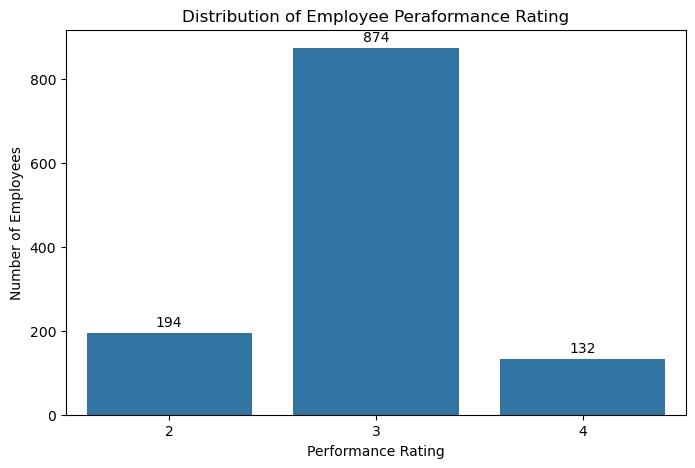

In [10]:
# Visualize PerformanceRating distribution

plt.figure(figsize = (8,5))

ax = sns.countplot(
    data = df,
    x = target_column
)

plt.title("Distribution of Employee Peraformance Rating")
plt.xlabel("Performance Rating")
plt.ylabel("Number of Employees")

# Add count values on the top of bars

for container in ax.containers:
    ax.bar_label(container, fmt = '%d', padding = 3) 


plt.show()


### Insight

The performance distribution shows whether the target classes are balanced or imbalanced. If one performance category contains substantially more employees than another, class imbalance should be considered when interpreting model performance.

## 6. DEPARTMENT-WISE PERFORMANCE

Department-wise analysis helps determine whether the distribution of employee performance differs across organizational departments.

### 6.1 Check Department Availability

In [12]:
# Check department availability

department_column = "EmpDepartment"

if department_column in df.columns:

    department_performance = (
        df.groupby(department_column)[target_column]
        .mean()
        .sort_values(ascending=False)
    )

    print(f"Average performance rating by department:")

    for department, rating in department_performance.items():

        print(
            f"{department}: "
            f"{rating:.2f}"
        )

else:

    department_performance = None

    print(f"Department column is not available.")


Average performance rating by department:
Development: 3.09
Data Science: 3.05
Human Resources: 2.93
Research & Development: 2.92
Sales: 2.86
Finance: 2.78


### 6.2 Visualization - Department-Wise Average Performance

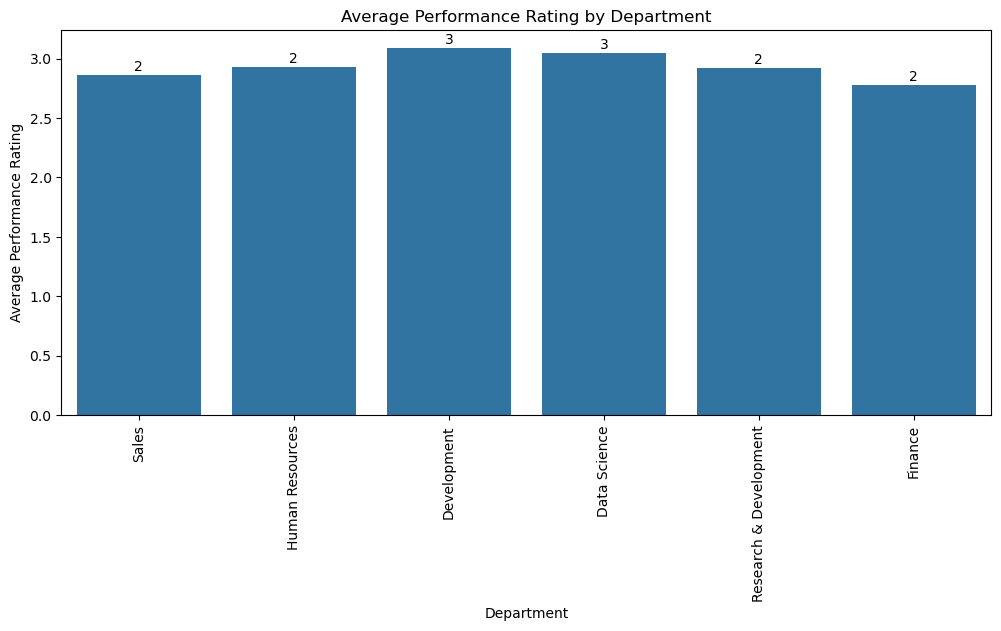

In [13]:
# Department-wise average performance

plt.figure(figsize = (12,5))

ax = sns.barplot(
    data = df,
    x = department_column,
    y = target_column,
    estimator = np.mean,
    errorbar = None
)

plt.title("Average Performance Rating by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Rating")
plt.xticks(rotation = 90)

for container in ax.containers:
    ax.bar_label(container, fmt = '%d', padding = 1)

plt.show()

### Insight

The department comparison highlights differences in average predicted or observed performance across organizational functions. These differences describe group-level patterns and do not imply that department membership causes performance differences.


## 7. DEPARTMENT-WISE PERFORMANCE RATING DISTRIBUTION

Average performance alone may hide differences between performance categories. Therefore, the distribution of each performance rating within departments is also visualized.

### 7.1 Create Department-Wise Performance Table


In [14]:
# Create department-wise performance table

if department_column in df.columns:

    department_rating_table = pd.crosstab(
        df[department_column],
        df[target_column]
    )

    print(f"Department-wise performance rating counts:")

    display(department_rating_table)

else:

    department_rating_table = None

    print(f"Department column is not available.")


Department-wise performance rating counts:


PerformanceRating,2,3,4
EmpDepartment,,,
Data Science,1,17,2
Development,13,304,44
Finance,15,30,4
Human Resources,10,38,6
Research & Development,68,234,41
Sales,87,251,35


### 7.2 Plot Department-Wise Performance Distribution

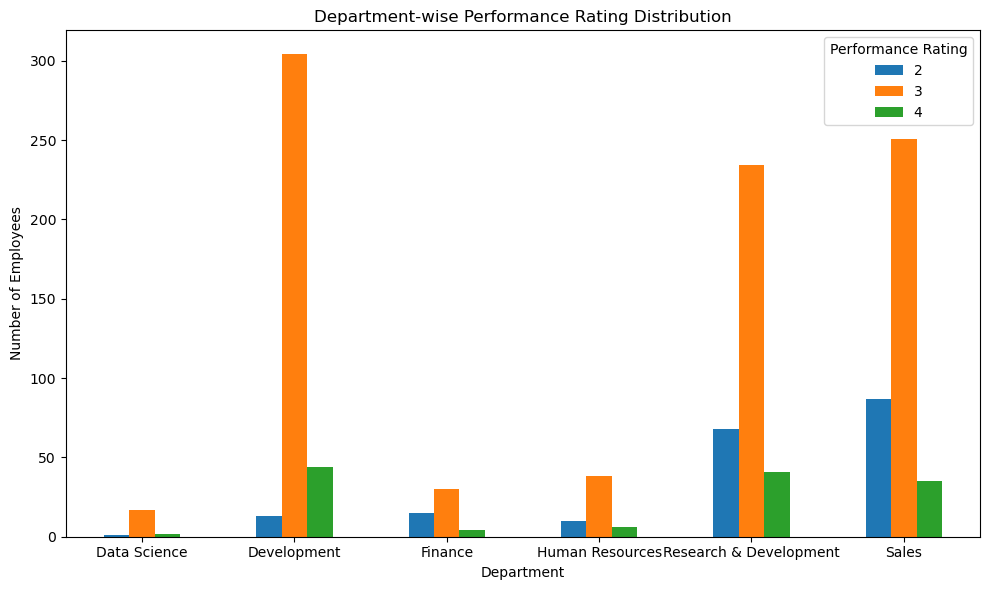

In [15]:
# Plot department-wise performance distribution

if department_rating_table is not None:

    department_rating_table.plot(
        kind="bar",
        figsize=(10, 6)
    )

    plt.title("Department-wise Performance Rating Distribution")
    plt.xlabel("Department")
    plt.ylabel("Number of Employees")
    plt.xticks(rotation=0)
    plt.legend(title="Performance Rating")
    plt.tight_layout()
    plt.show()

else:

    print(f"Department-wise distribution visualization skipped.")


### Insight


This visualization shows how different performance categories are distributed across departments and provides more detail than comparing department averages alone.


## 8. EMPLOYEE SATISFACTION ANALYSIS

Employee satisfaction variables can be explored to understand their relationship with performance.
Common satisfaction variables in the INX employee dataset include environment satisfaction, job satisfaction, and relationship satisfaction.


### 8.1 Identify Available Satisfaction Columns

In [17]:
# Identify available satisfaction columns

satisfaction_columns = [
    "EmpEnvironmentSatisfaction",
    "EmpJobSatisfaction",
    "EmpRelationshipSatisfaction"
]

available_satisfaction = [
    column
    for column in satisfaction_columns
    if column in df.columns
]

print(f"Available satisfaction variables:")

for column in available_satisfaction:

    print(f"- {column}")


Available satisfaction variables:
- EmpEnvironmentSatisfaction
- EmpJobSatisfaction
- EmpRelationshipSatisfaction


### 8.2 Analyze Satisfaction Against Performance

In [19]:
# Analyze satisfaction against performance

for column in available_satisfaction:

    satisfaction_performance = (
        df.groupby(column)[target_column]
        .mean()
    )

    print(f"\nAverage performance by {column}:")

    for level, rating in satisfaction_performance.items():

        print(
            f"{column} = {level}: "
            f"{rating:.2f}"
        )



Average performance by EmpEnvironmentSatisfaction:
EmpEnvironmentSatisfaction = 1: 2.67
EmpEnvironmentSatisfaction = 2: 2.65
EmpEnvironmentSatisfaction = 3: 3.14
EmpEnvironmentSatisfaction = 4: 3.13

Average performance by EmpJobSatisfaction:
EmpJobSatisfaction = 1: 2.97
EmpJobSatisfaction = 2: 2.95
EmpJobSatisfaction = 3: 2.90
EmpJobSatisfaction = 4: 2.98

Average performance by EmpRelationshipSatisfaction:
EmpRelationshipSatisfaction = 1: 2.95
EmpRelationshipSatisfaction = 2: 2.96
EmpRelationshipSatisfaction = 3: 2.97
EmpRelationshipSatisfaction = 4: 2.92


### 8.3 Create Satisfication Visualization

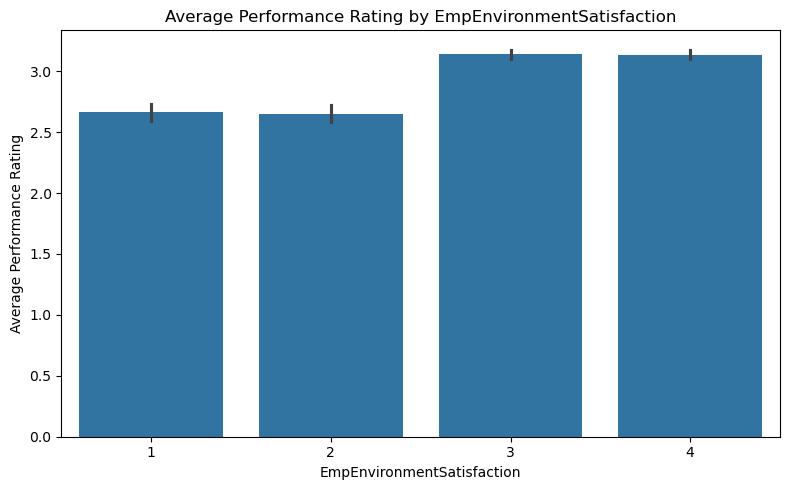

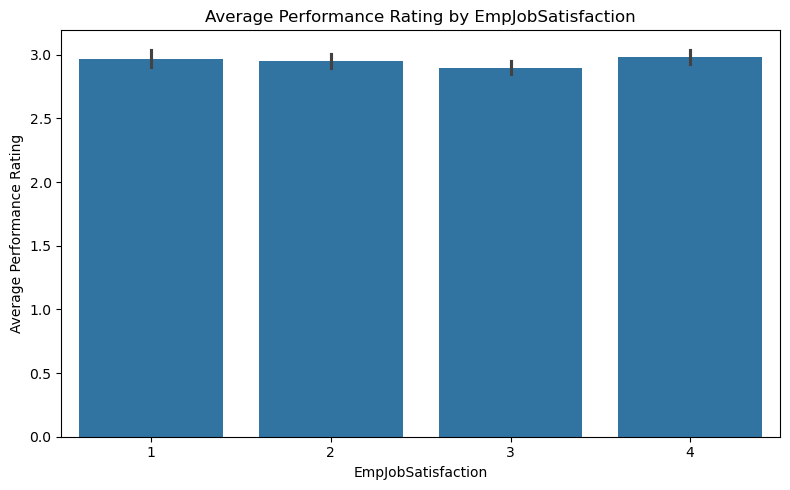

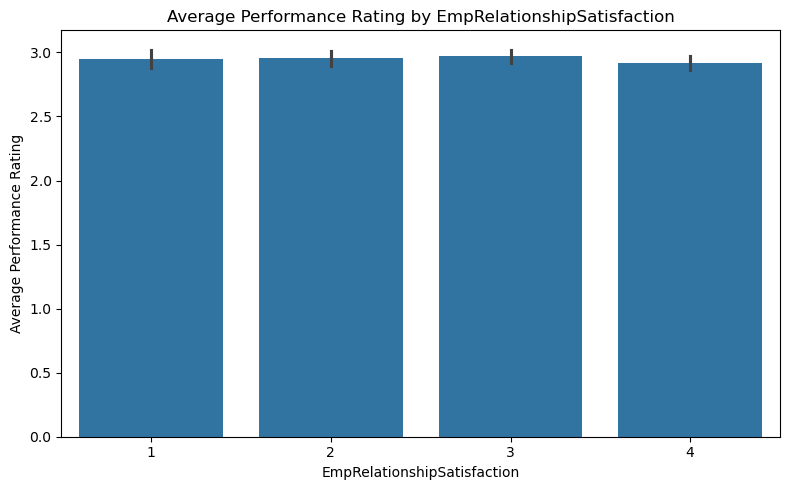

In [20]:
# Create satisfaction visualizations

for column in available_satisfaction:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=df,
        x=column,
        y=target_column
    )

    plt.title(
        f"Average Performance Rating by {column}"
    )

    plt.xlabel(column)
    plt.ylabel("Average Performance Rating")

    plt.tight_layout()
    plt.show()


### Insight

The satisfaction analysis shows whether different satisfaction levels are associated with differences in average performance ratings. These are associations in the dataset and should not be interpreted as proof of causation.

## 9. SALARY HIKE ANALYSIS

The PercentSalaryHike variable represents the percentage salary increase received by an employee.

Analyzing this variable against performance can help identify whether performance ratings differ across salary-hike levels.


### 9.1 Check Salary Hike Column

In [23]:
# Check salary hike column

salary_hike_column = "EmpLastSalaryHikePercent"

if salary_hike_column in df.columns:

    print(f"Salary hike column found.")
    print(
        f"Minimum salary hike: "
        f"{df[salary_hike_column].min():.2f}%"
    )

    print(
        f"Maximum salary hike: "
        f"{df[salary_hike_column].max():.2f}%"
    )

    print(
        f"Average salary hike: "
        f"{df[salary_hike_column].mean():.2f}%"
    )

else:

    print(f"Salary hike column is not available.")


Salary hike column found.
Minimum salary hike: 11.00%
Maximum salary hike: 25.00%
Average salary hike: 15.22%


### 9.1 Plot Salary Hike Against Performance

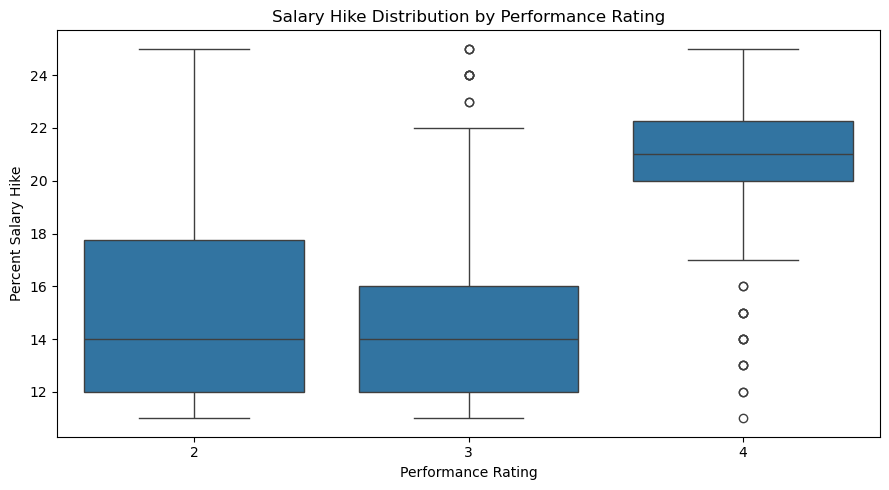

In [24]:
if salary_hike_column in df.columns:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x=target_column,
        y=salary_hike_column
    )

    plt.title(
        "Salary Hike Distribution by Performance Rating"
    )

    plt.xlabel("Performance Rating")
    plt.ylabel("Percent Salary Hike")

    plt.tight_layout()
    plt.show()

else:

    print(f"Salary hike visualization skipped.")


### Insight

The boxplot shows the distribution of salary hikes across performance categories. Differences between groups can reveal patterns worth investigating further.


## 10. PROMOTION ANALYSIS

Promotion-related variables such as YearsSinceLastPromotion can be analyzed to understand their relationship with employee performance.

### 10.1 Check Promotion-related Variable

In [25]:
# Check promotion-related variable

promotion_column = "YearsSinceLastPromotion"

if promotion_column in df.columns:

    promotion_performance = (
        df.groupby(promotion_column)[target_column]
        .mean()
    )

    print(f"Average performance by years since last promotion:")

    for years, rating in promotion_performance.items():

        print(
            f"{years} years: "
            f"{rating:.2f}"
        )

else:

    promotion_performance = None

    print(f"Promotion variable is not available.")


Average performance by years since last promotion:
0 years: 3.12
1 years: 2.90
2 years: 2.76
3 years: 2.78
4 years: 2.77
5 years: 2.83
6 years: 2.83
7 years: 2.85
8 years: 2.55
9 years: 2.69
10 years: 2.60
11 years: 2.83
12 years: 2.67
13 years: 3.12
14 years: 3.00
15 years: 2.91


### 10.2 Plot Promotion Relationship

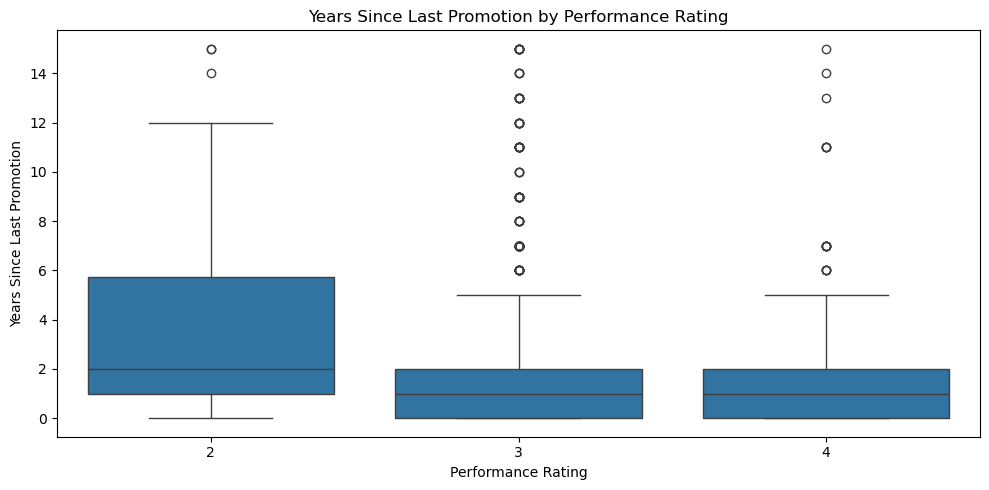

In [26]:
# Plot promotion relationship

if promotion_column in df.columns:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x=target_column,
        y=promotion_column
    )

    plt.title(
        "Years Since Last Promotion by Performance Rating"
    )

    plt.xlabel("Performance Rating")
    plt.ylabel("Years Since Last Promotion")

    plt.tight_layout()
    plt.show()

else:

    print(f"Promotion visualization skipped.")


### Insight

The visualization allows comparison of promotion-related tenure across performance categories. It can help identify whether employees in different performance groups have different promotion histories.


## 11. WORK-LIFE BALANCE ANALYSIS

Work-life balance is another employee-related factor that can be explored in relation to performance.

### 11.1 Check work-Like Balance Variable

In [28]:
# Check work-life balance variable

worklife_column = "EmpWorkLifeBalance"

if worklife_column in df.columns:

    worklife_performance = (
        df.groupby(worklife_column)[target_column]
        .mean()
    )

    print(f"Average performance by work-life balance:")

    for level, rating in worklife_performance.items():

        print(
            f"Work-Life Balance {level}: "
            f"{rating:.2f}"
        )

else:

    worklife_performance = None

    print(f"Work-life balance column is not available.")


Average performance by work-life balance:
Work-Life Balance 1: 2.75
Work-Life Balance 2: 2.92
Work-Life Balance 3: 2.95
Work-Life Balance 4: 3.12


### 11.2 Plot Work-Life Balance Against Performance

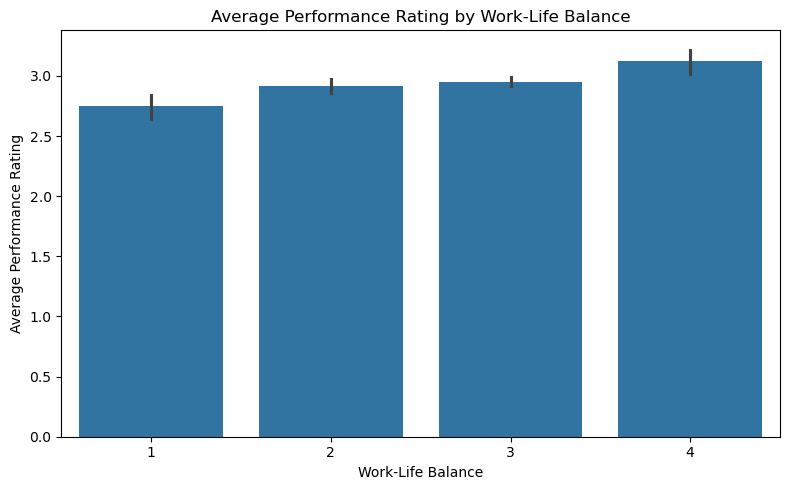

In [29]:
# Plot work-life balance against performance

if worklife_column in df.columns:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=df,
        x=worklife_column,
        y=target_column
    )

    plt.title(
        "Average Performance Rating by Work-Life Balance"
    )

    plt.xlabel("Work-Life Balance")
    plt.ylabel("Average Performance Rating")

    plt.tight_layout()
    plt.show()

else:

    print(f"Work-life balance visualization skipped.")


### Insight

The visualization compares average performance across work-life balance levels. The relationship should be interpreted as an observed association within the dataset.


## 12. CORRELATION HEATMAP

Correlation analysis helps identify linear relationships between numerical variables.

A correlation coefficient ranges from -1 to +1. Values closer to +1 indicate stronger positive linear association, while values closer to -1 indicate stronger negative linear association.


### 12.1 Select Numerical Columns

In [30]:
# Select numerical columns

numerical_df = df.select_dtypes(
    include=np.number
)

print(
    f"Number of numerical variables: "
    f"{numerical_df.shape[1]}"
)

print(f"Numerical variables:")

for column in numerical_df.columns:

    print(f"- {column}")


Number of numerical variables: 19
Numerical variables:
- Age
- DistanceFromHome
- EmpEducationLevel
- EmpEnvironmentSatisfaction
- EmpHourlyRate
- EmpJobInvolvement
- EmpJobLevel
- EmpJobSatisfaction
- NumCompaniesWorked
- EmpLastSalaryHikePercent
- EmpRelationshipSatisfaction
- TotalWorkExperienceInYears
- TrainingTimesLastYear
- EmpWorkLifeBalance
- ExperienceYearsAtThisCompany
- ExperienceYearsInCurrentRole
- YearsSinceLastPromotion
- YearsWithCurrManager
- PerformanceRating


### 12.2 Calculate Correlation Matrix

In [31]:
# Calculate correlation matrix

correlation_matrix = numerical_df.corr()

print(f"Correlation matrix calculated successfully.")

display(correlation_matrix.round(2))


Correlation matrix calculated successfully.


,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating
Age,1.00,0.02,0.21,0.01,0.06,0.03,0.51,-0.00,0.28,-0.01,0.05,0.68,-0.02,-0.02,0.32,0.22,0.23,0.21,-0.04
DistanceFromHome,0.02,1.00,0.05,-0.02,0.01,0.00,0.02,-0.00,-0.02,0.04,-0.01,0.03,-0.03,-0.04,0.02,0.02,0.01,0.02,-0.05
EmpEducationLevel,0.21,0.05,1.00,-0.04,0.01,0.03,0.10,0.00,0.13,0.00,-0.02,0.15,-0.01,0.01,0.08,0.07,0.05,0.09,0.02
EmpEnvironmentSatisfaction,0.01,-0.02,-0.04,1.00,-0.05,0.00,-0.01,-0.00,0.02,-0.05,-0.01,-0.01,0.00,-0.00,-0.00,0.03,0.01,-0.01,0.40
EmpHourlyRate,0.06,0.01,0.01,-0.05,1.00,0.05,-0.02,-0.07,0.04,-0.02,0.01,0.03,-0.02,0.02,-0.00,-0.01,-0.01,-0.00,-0.04
EmpJobInvolvement,0.03,0.00,0.03,0.00,0.05,1.00,-0.03,-0.01,0.02,-0.00,0.02,-0.03,-0.03,-0.01,-0.04,0.00,-0.02,0.01,-0.01
EmpJobLevel,0.51,0.02,0.10,-0.01,-0.02,-0.03,1.00,-0.01,0.13,-0.02,0.00,0.78,-0.00,0.05,0.54,0.40,0.36,0.37,-0.08
EmpJobSatisfaction,-0.00,-0.00,0.00,-0.00,-0.07,-0.01,-0.01,1.00,-0.05,0.03,-0.02,-0.03,-0.03,-0.02,0.00,0.00,-0.01,-0.02,0.00
NumCompaniesWorked,0.28,-0.02,0.13,0.02,0.04,0.02,0.13,-0.05,1.00,-0.01,0.06,0.22,-0.05,0.00,-0.13,-0.10,-0.03,-0.11,0.02
EmpLastSalaryHikePercent,-0.01,0.04,0.00,-0.05,-0.02,-0.00,-0.02,0.03,-0.01,1.00,-0.04,-0.01,-0.01,-0.02,-0.02,-0.00,-0.02,-0.01,0.33


### 12.3 Plot Correlation Heatmap



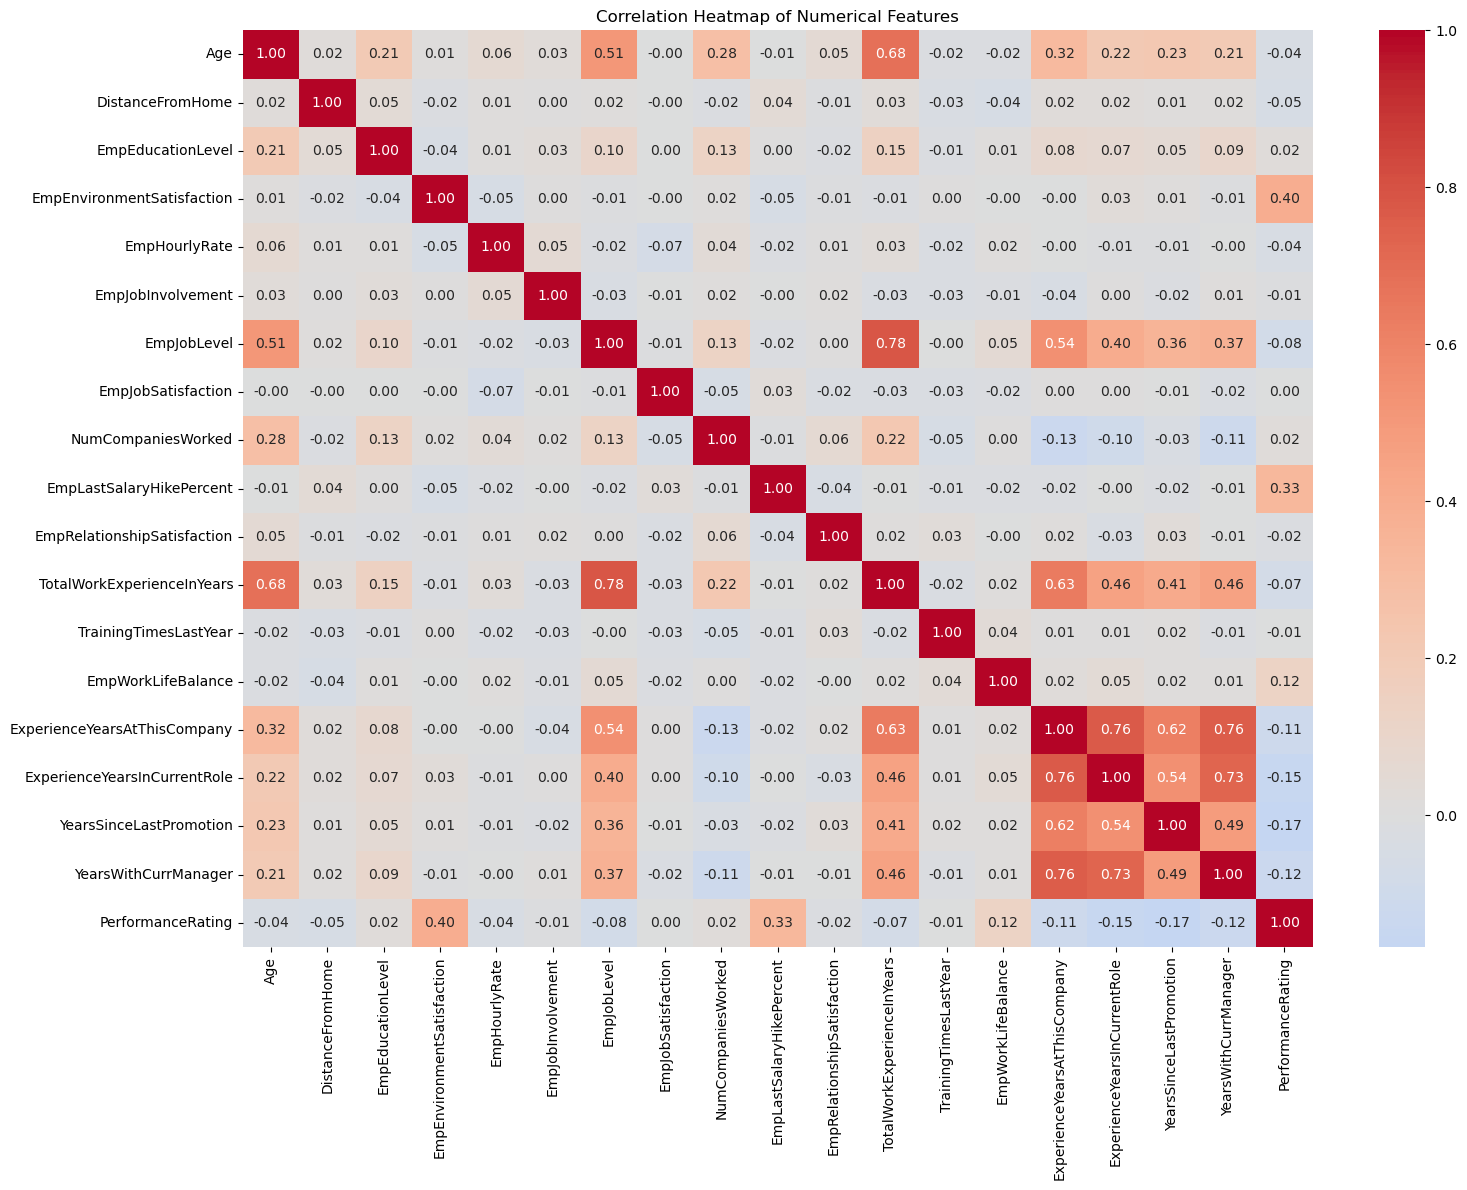

In [32]:
# Plot correlation heatmap

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


### Insight

The correlation heatmap provides an overview of relationships between numerical variables. Correlation indicates association and should not be interpreted as evidence that one variable causes another.


## 13. TOP THREE IMPORTANT FACTORS

The trained model's permutation importance can be used to identify the three original employee variables that most strongly affect model performance.

Permutation importance is particularly useful here because it evaluates the effect of randomly shuffling an input feature while keeping the other features unchanged.


### 13.1 Define Model Path

In [34]:
import os
import joblib

# Get the project root directory
project_root = os.path.abspath(
    os.path.join(os.getcwd(), "..", "..")
)

# Define model path
model_path = os.path.join(
    project_root,
    "src",
    "models"
)

# Define trained model file
model_file = os.path.join(
    model_path,
    "employee_performance_model.joblib"
)

print(f"Project root: {project_root}")
print(f"Model directory: {model_path}")
print(f"Model file: {model_file}")

if os.path.exists(model_file):

    trained_model = joblib.load(model_file)

    print("Trained model loaded successfully.")

else:

    trained_model = None

    print("Trained model file was not found.")

Project root: E:\IABAC\INX_Future_Inc_Employee_Performance
Model directory: E:\IABAC\INX_Future_Inc_Employee_Performance\src\models
Model file: E:\IABAC\INX_Future_Inc_Employee_Performance\src\models\employee_performance_model.joblib
Trained model loaded successfully.


### 13.2 Calculate Permutation Importance if it was not saved previously

In [37]:
# Calculate permutation importance if it was not saved previously

from sklearn.inspection import permutation_importance

if permutation_df is None and trained_model is not None:

    if target_column in df.columns:

        X_visual = df.drop(
            columns=[target_column]
        )

        y_visual = df[target_column]

        permutation_result = permutation_importance(
            trained_model,
            X_visual,
            y_visual,
            scoring="f1_weighted",
            n_repeats=10,
            random_state=42,
            n_jobs=-1
        )

        permutation_df = pd.DataFrame({
            "Feature": X_visual.columns,
            "Importance_Mean": permutation_result.importances_mean,
            "Importance_Std": permutation_result.importances_std
        }).sort_values(
            by="Importance_Mean",
            ascending=False
        ).reset_index(drop=True)

        print(
            f"Permutation importance calculated successfully."
        )

    else:

        print(
            f"Target variable is unavailable for permutation importance."
        )


Permutation importance calculated successfully.


### 13.3 Display Top Three Factors

In [38]:
# Display top three factors

if permutation_df is not None:

    top_three_factors = (
        permutation_df
        .head(3)
        .copy()
    )

    print(f"Top three model-associated factors:")

    for index, row in top_three_factors.iterrows():

        print(
            f"{index + 1}. "
            f"{row['Feature']} "
            f"(Importance: {row['Importance_Mean']:.6f})"
        )

else:

    top_three_factors = pd.DataFrame()

    print(
        f"Top three factors could not be calculated."
    )


Top three model-associated factors:
1. EmpEnvironmentSatisfaction (Importance: 0.197505)
2. EmpLastSalaryHikePercent (Importance: 0.143100)
3. YearsSinceLastPromotion (Importance: 0.095401)


### Insight

The top three factors represent the employee variables that contributed most to predictive performance, according to permutation importance.

These should be described as model-associated predictive factors, not as proven causal factors.


## 14. FEATURE IMPORTANCE VISUALIZATION

A visual representation makes it easier to communicate the relative importance of the variables identified by the model.

### 14.1 Plot Top Feature Importance Values

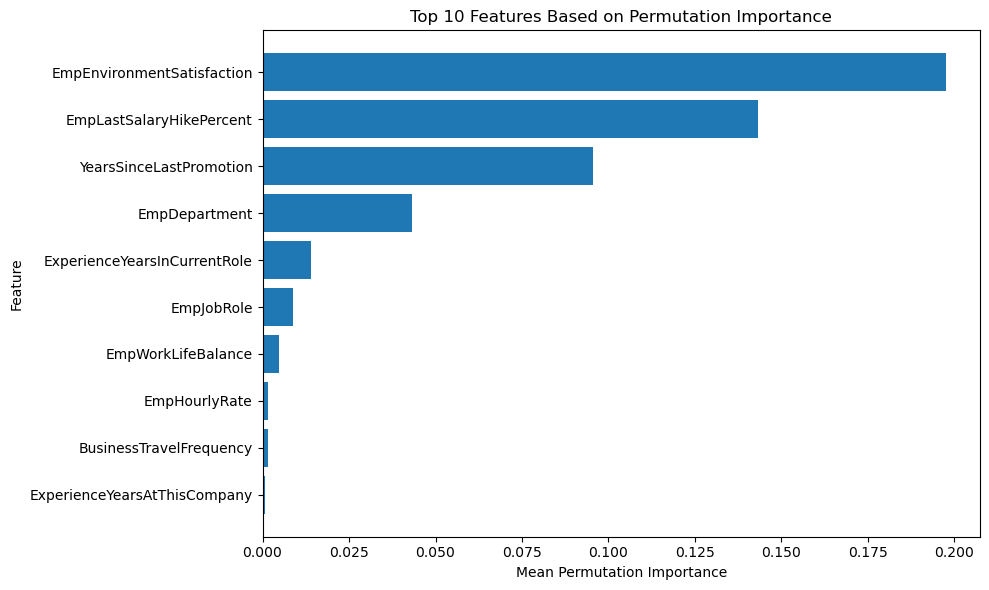

In [39]:
# Plot top feature importance values

if permutation_df is not None and not permutation_df.empty:

    top_features = (
        permutation_df
        .head(10)
        .sort_values(
            by="Importance_Mean",
            ascending=True
        )
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        top_features["Feature"],
        top_features["Importance_Mean"]
    )

    plt.title(
        "Top 10 Features Based on Permutation Importance"
    )

    plt.xlabel(
        "Mean Permutation Importance"
    )

    plt.ylabel(
        "Feature"
    )

    plt.tight_layout()
    plt.show()

else:

    print(
        f"Feature importance visualization skipped."
    )


### Insight

The feature importance chart provides a clear visual ranking of the variables that contribute most to the model's predictive performance.


## 15. MODEL PERFORMANCE COMPARISON

The model training stage compared Logistic Regression, Support Vector Machine, and Random Forest.

The evaluation results can be loaded if they were saved during model training. If a results file is unavailable, the models can be evaluated again using the processed dataset.


### 15.1 Importing Libraries



In [60]:
# Import libraries

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

### 15.2 Display Selected Features Names

In [49]:
# Display selected feature names

print("Selected features:\n")

for index, column in enumerate(X.columns, start = 1):
    print(f"{index}. {column}")

Selected features:

1. Age
2. Gender
3. EducationBackground
4. MaritalStatus
5. EmpDepartment
6. EmpJobRole
7. BusinessTravelFrequency
8. DistanceFromHome
9. EmpEducationLevel
10. EmpEnvironmentSatisfaction
11. EmpHourlyRate
12. EmpJobInvolvement
13. EmpJobLevel
14. EmpJobSatisfaction
15. NumCompaniesWorked
16. OverTime
17. EmpLastSalaryHikePercent
18. EmpRelationshipSatisfaction
19. TotalWorkExperienceInYears
20. TrainingTimesLastYear
21. EmpWorkLifeBalance
22. ExperienceYearsAtThisCompany
23. ExperienceYearsInCurrentRole
24. YearsSinceLastPromotion
25. YearsWithCurrManager


### 15.3 Identify Numerical and Categorical Features

In [50]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include = np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include = ["object", "category", "bool"]
).columns.tolist()

print(f"Number of numerical features: {len(numerical_features)}\n")
print(f"Number of categorical features: {len(categorical_features)}\n")

print(f"Numerical features: {numerical_features}\n")
print(f"Categorical features: {categorical_features}")

Number of numerical features: 18

Number of categorical features: 7

Numerical features: ['Age', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical features: ['Gender', 'EducationBackground', 'MaritalStatus', 'EmpDepartment', 'EmpJobRole', 'BusinessTravelFrequency', 'OverTime']


### 15.4 Display Missing Values In X and y

In [51]:
# Display missing values in X and y

print(
    f"Total missing values in features:"
    f"{X.isnull().sum().sum()}"
)

print(
    f"Total missing values in target:"
    f"{y.isnull().sum().sum()}"
)

Total missing values in features:0
Total missing values in target:0


### 15.5 Display Target Distribution

In [52]:
# Display target distribution

target_counts = y.value_counts().sort_index()

print("Target class distribution:")

for class_value, count in target_counts.items():
    percentage = (
        count / len(y)
    )* 100

    print(
    f"Class {class_value}:"
    f"{count} employees"
    f"({percentage:.2f}%)"
    )

Target class distribution:
Class 2:194 employees(16.17%)
Class 3:874 employees(72.83%)
Class 4:132 employees(11.00%)


### 15.6 Split Dataset Into Training and Testing Sets

In [53]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print(f"Training feature shape: {X_train.shape}")
print(f"Testing feature shape: {y_test.shape}")

print(f"Training target size: {y_train.shape[0]}")
print(f"Testing target size: {y_test.shape[0]}")

Training feature shape: (960, 25)
Testing feature shape: (240,)
Training target size: 960
Testing target size: 240


### 15.7 Categorical Preprocessing Pipeline

In [54]:
# Categorical preprocessing pipeline

categorical_pipeline = Pipeline(
steps = [
    (
        "imputer",
        SimpleImputer(strategy = "most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown = "ignore"
        )
    )
    ]
)

print("Numerical preprocessing pipeline created.")
print("Categorical preprocessing pipeline created.")



Numerical preprocessing pipeline created.
Categorical preprocessing pipeline created.


### 15.8 Combine Numerical and Categorical Preprocessing

In [55]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers = [
        (
            "numerical",
            numerical_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder = "drop"
)

print("Column Transformer preprocessing pipeline created.")

Column Transformer preprocessing pipeline created.


### 15.8 Create All Model Pipeline

In [56]:
# Create Logistic Regression pipeline

logistic_model = Pipeline(
    steps = [
        (
        "preprocessor",
        preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter = 2000,
                random_state = 42
            )
        )
    ]
)

# Train Logistic Regression

logistic_model.fit(
    X_train,
    y_train
)

# Create Support Vector Pipeline

svm_model = Pipeline(
    steps = [
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            SVC(
                kernel = "rbf",
                random_state = 42
            )
        )
    ]
)

# Train SVM

svm_model.fit(
    X_train,
    y_train
)

# Create Random Forest pipeline

random_forest_model = Pipeline(
    steps = [
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators = 300,
                random_state = 42,
                n_jobs = -1
            )
        )
    ]
)

# Train Random Forest
random_forest_model.fit(
    X_train,
    y_train
)

# Store trained models

models = {
    "Logistic Regression": logistic_model,
    "Support Vector Machine": svm_model,
    "Random Forest": random_forest_model
}

print(f"Number of trained models: {len(models)}")

for model_name in models:
    print(f"- {model_name}")

# Evaluate models

evaluation_results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(
    y_test,
    y_pred
    )

    precision = precision_score(
    y_test,
    y_pred,
    average = "weighted",
    zero_division = 0
    )

    recall = recall_score(
    y_test,
    y_pred,
    average = "weighted",
    zero_division = 0
    )

    f1 = f1_score(
    y_test,
    y_pred,
    average = "weighted",
    zero_division = 0
    )

    evaluation_results.append({
    "Model": model_name,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1
    })

Number of trained models: 3
- Logistic Regression
- Support Vector Machine
- Random Forest


### 15.9 Display Model Comparsion

In [59]:
print(
    f"{model_name}:"
    f"Accuracy = {accuracy:.4f},"
    f"Precision = {precision:.4f},"
    f"Recall = {recall:.4f},"
    f"F1 = {f1:.4f}"
    )

evaluation_df = pd.DataFrame(
    evaluation_results
    )

display(evaluation_results)

Random Forest:Accuracy = 0.9167,Precision = 0.9196,Recall = 0.9167,F1 = 0.9132


[{'Model': 'Logistic Regression',
  'Accuracy': 0.8208333333333333,
  'Precision': 0.8127124451754386,
  'Recall': 0.8208333333333333,
  'F1_Score': 0.813047329561414},
 {'Model': 'Support Vector Machine',
  'Accuracy': 0.825,
  'Precision': 0.8328304048892284,
  'Recall': 0.825,
  'F1_Score': 0.8014676339285713},
 {'Model': 'Random Forest',
  'Accuracy': 0.9166666666666666,
  'Precision': 0.9196408529741862,
  'Recall': 0.9166666666666666,
  'F1_Score': 0.9131555944055945}]

### 15.10 Plot Model Performance Comparison

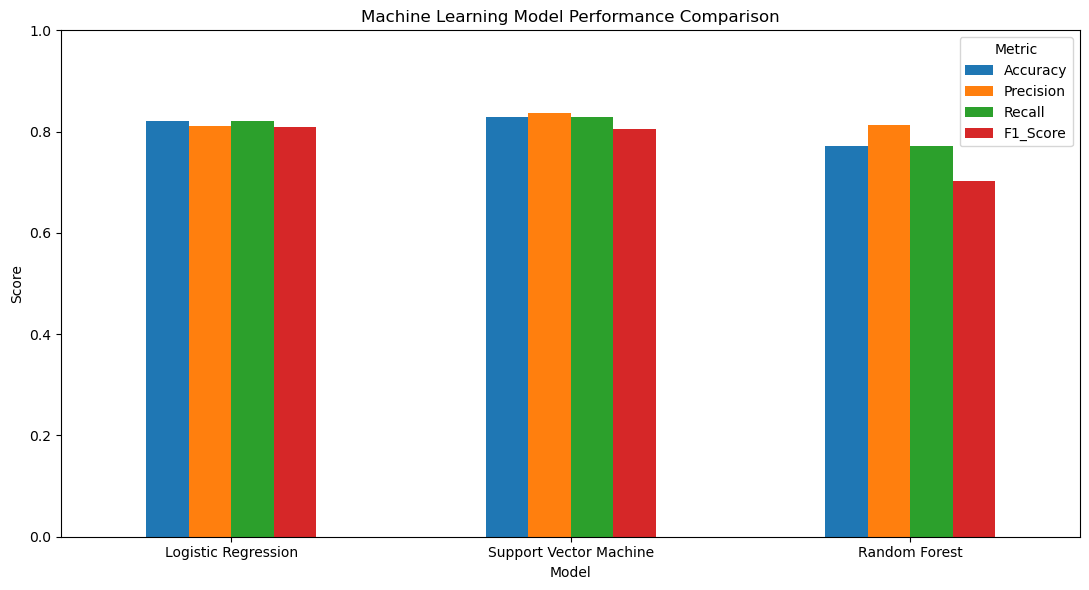

In [61]:
# Plot model performance comparison

if model_comparison is not None:

    comparison_columns = [
        "Accuracy",
        "Precision",
        "Recall",
        "F1_Score"
    ]

    available_metrics = [
        column
        for column in comparison_columns
        if column in model_comparison.columns
    ]

    if "Model" in model_comparison.columns:

        plot_data = model_comparison.set_index(
            "Model"
        )[available_metrics]

        plot_data.plot(
            kind="bar",
            figsize=(11, 6)
        )

        plt.title(
            "Machine Learning Model Performance Comparison"
        )

        plt.xlabel(
            "Model"
        )

        plt.ylabel(
            "Score"
        )

        plt.ylim(
            0,
            1
        )

        plt.xticks(
            rotation=0
        )

        plt.legend(
            title="Metric"
        )

        plt.tight_layout()
        plt.show()

else:

    print(
        f"Model performance visualization skipped."
    )

### Insight

The model comparison chart provides a visual comparison of accuracy, precision, recall, and F1-score across the candidate algorithms.


## 16. CONFUSION MATRIX VISUALIZATION

A confusion matrix provides a detailed view of the classification results by comparing actual performance ratings with predicted performance ratings.

### 16.1 Define the Selected Model

In [70]:
# Define the selected model

best_model = random_forest_model

best_model_name = "Random Forest"

print(f"Selected model: {best_model_name}")

Selected model: Random Forest


### 16.2 Plot Confusion Matrix

Predictions generated successfully.
Confusion matrix calculated:
[[ 30   9   0]
 [  3 172   0]
 [  0   8  18]]


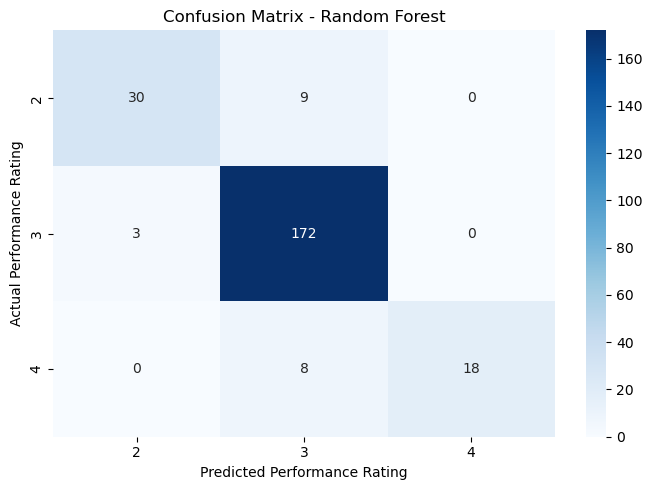

In [71]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Generate predictions using the best model

y_pred = best_model.predict(X_test)

print("Predictions generated successfully.")


# Calculate confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion matrix calculated:")
print(cm)


# Get actual PerformanceRating classes

class_labels = sorted(
    y_test.unique()
)


# Plot confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel(
    "Predicted Performance Rating"
)

plt.ylabel(
    "Actual Performance Rating"
)

plt.tight_layout()

plt.show()

### Insight

The confusion matrix shows which performance categories are correctly classified and which categories are confused by the model.
Large values along the diagonal indicate correct classifications, while values away from the diagonal represent prediction errors.


## 17. KEY VISUAL INSIGHTS

The major visual findings from the notebook are summarized below.

### 17.1 Generate Key Visual Insights

In [73]:
# Generate key visual insights

print(f"KEY VISUAL INSIGHTS")
print(f"=" * 80)

if target_column in df.columns:

    print(
        f"1. Employee performance ratings were analyzed "
        f"across the available performance categories."
    )

if department_column in df.columns:

    print(
        f"2. Department-wise analysis was performed "
        f"to compare employee performance patterns."
    )

if available_satisfaction:

    print(
        f"3. Employee satisfaction variables were compared "
        f"with performance ratings."
    )

if salary_hike_column in df.columns:

    print(
        f"4. Salary hike distributions were analyzed "
        f"across performance categories."
    )

if promotion_column in df.columns:

    print(
        f"5. Promotion history was analyzed "
        f"in relation to performance."
    )

if worklife_column in df.columns:

    print(
        f"6. Work-life balance was analyzed "
        f"against employee performance."
    )

if numerical_df.shape[1] > 1:

    print(
        f"7. Correlations between numerical employee variables "
        f"were visualized using a heatmap."
    )

if permutation_df is not None:

    print(
        f"8. Model-associated important factors were "
        f"identified using permutation importance."
    )

if model_comparison is not None:

    print(
        f"9. Candidate machine learning models were "
        f"compared using evaluation metrics."
    )

print(f"=" * 80)


KEY VISUAL INSIGHTS
1. Employee performance ratings were analyzed across the available performance categories.
2. Department-wise analysis was performed to compare employee performance patterns.
3. Employee satisfaction variables were compared with performance ratings.
4. Salary hike distributions were analyzed across performance categories.
5. Promotion history was analyzed in relation to performance.
6. Work-life balance was analyzed against employee performance.
7. Correlations between numerical employee variables were visualized using a heatmap.
8. Model-associated important factors were identified using permutation importance.
9. Candidate machine learning models were compared using evaluation metrics.


### Insight

The visual analysis provides a consolidated view of employee performance patterns, employee characteristics, and machine learning model behavior.


## 18. BUSINESS INSIGHTS

The visualization results can be translated into business-oriented observations that may help HR teams understand employee performance patterns.

### 18.1 Generate Business-Oriented Insights

In [75]:
# Generate business-oriented insights

print(f"BUSINESS INSIGHTS")
print(f"=" * 80)

print(
    f"1. Employee performance can be analyzed "
    f"across different organizational departments."
)

print(
    f"2. Employee satisfaction indicators can be "
    f"examined alongside performance ratings."
)

print(
    f"3. Salary hike and promotion history can be "
    f"used to understand performance-related patterns."
)

print(
    f"4. Work-life balance can be included as one of "
    f"the employee-related factors in performance analysis."
)

print(
    f"5. Machine learning feature importance can help "
    f"identify variables associated with prediction."
)

print(
    f"6. Model performance metrics can be monitored "
    f"to understand classification quality."
)

print(
    f"7. Visual findings should be combined with HR "
    f"expertise and organizational context before action."
)

print(f"=" * 80)


BUSINESS INSIGHTS
1. Employee performance can be analyzed across different organizational departments.
2. Employee satisfaction indicators can be examined alongside performance ratings.
3. Salary hike and promotion history can be used to understand performance-related patterns.
4. Work-life balance can be included as one of the employee-related factors in performance analysis.
5. Machine learning feature importance can help identify variables associated with prediction.
6. Model performance metrics can be monitored to understand classification quality.
7. Visual findings should be combined with HR expertise and organizational context before action.


### Insight

The visualization results can support HR analytics, employee development, training planning, and workforce analysis. However, visual associations should not automatically be interpreted as causal relationships.


## 19. CONCLUSION

This visualization notebook successfully presents the major analytical and machine learning results of the INX Future Inc Employee Performance project.
The notebook visualized employee performance distribution, department-wise performance, performance rating distribution, employee satisfaction, salary hike, promotion history, work-life balance, numerical correlations, model-associated important factors, model performance comparison, and the confusion matrix.
These visualizations provide an accessible way to communicate the project's technical findings and business insights. They can be incorporated into the final project report and presentation to demonstrate both the analytical process and the machine learning results.


### 19.1 Final Visualization Summary

In [76]:
print(f"=" * 70)
print(f"INX FUTURE INC EMPLOYEE PERFORMANCE")
print(f"DATA VISUALIZATION SUMMARY")
print(f"=" * 70)

print(
    f"Dataset rows visualized: "
    f"{df.shape[0]}"
)

print(
    f"Dataset columns analyzed: "
    f"{df.shape[1]}"
)

print(
    f"Target variable: "
    f"{target_column}"
)

print(
    f"Department analysis available: "
    f"{department_column in df.columns}"
)

print(
    f"Satisfaction analysis variables available: "
    f"{len(available_satisfaction)}"
)

print(
    f"Salary hike analysis available: "
    f"{salary_hike_column in df.columns}"
)

print(
    f"Promotion analysis available: "
    f"{promotion_column in df.columns}"
)

print(
    f"Work-life balance analysis available: "
    f"{worklife_column in df.columns}"
)

print(
    f"Feature importance analysis available: "
    f"{permutation_df is not None}"
)

print(
    f"Model comparison available: "
    f"{model_comparison is not None}"
)

print(f"=" * 70)
print(f"Data visualization workflow completed successfully.")
print(f"=" * 70)


INX FUTURE INC EMPLOYEE PERFORMANCE
DATA VISUALIZATION SUMMARY
Dataset rows visualized: 1200
Dataset columns analyzed: 28
Target variable: PerformanceRating
Department analysis available: True
Satisfaction analysis variables available: 3
Salary hike analysis available: True
Promotion analysis available: True
Work-life balance analysis available: True
Feature importance analysis available: True
Model comparison available: True
Data visualization workflow completed successfully.
